# TP6 · Spacy et Hugging Face
**ISM École d'ingénieurs · Python avancé · L3 IA · Elias BADJI** — Binôme : Étudiant 1 : SENE Papa Arona · Étudiant 2 : NDIAYE ……

Ce notebook s'exécute de haut en bas avec « Redémarrer et tout exécuter ». Les cellules **Conclusion** et les réponses **[Interprétation]** sont à rédiger *après* lecture des sorties, avec chiffres et exemples cités.

**Fichiers de données :** `avis_clients.csv` et `messages_service_client.csv` sont retrouvés automatiquement (dossier du notebook, Téléchargements ou .zip) ; le mieux est de les copier à côté du notebook.
**Installation :** automatique dans la première cellule de code.

In [1]:
# Installation automatique des bibliothèques manquantes (première exécution seulement)
import sys, importlib.util, subprocess
print("Python", sys.version.split()[0])
if sys.version_info >= (3, 13):
    print("ATTENTION : spaCy, PyTorch ou transformers peuvent ne pas encore exister pour cette version de Python. "
          "En cas d'échec de l'installation, utilisez Python 3.11 ou 3.12 (ou Google Colab).")
paquets = {"spacy": "spacy", "transformers": "transformers", "tokenizers": "tokenizers", "torch": "torch",
           "accelerate": "accelerate>=1.1.0", "sklearn": "scikit-learn", "pandas": "pandas", "matplotlib": "matplotlib", "IPython": "ipython"}
manquants = [p for m, p in paquets.items() if importlib.util.find_spec(m) is None]
if manquants:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *manquants])
try:                                               # transformers récent : le Trainer exige accelerate >= 1.1.0
    from importlib.metadata import version
    if tuple(int(x) for x in version("accelerate").split(".")[:2]) < (1, 1):
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "accelerate>=1.1.0"])
except Exception:
    pass
if importlib.util.find_spec("fr_core_news_md") is None:
    subprocess.check_call([sys.executable, "-m", "spacy", "download", "fr_core_news_md"])
print("Bibliothèques prêtes. Si une installation vient d'avoir lieu, relancez le noyau (Restart) puis « Tout exécuter ».")

Python 3.14.3
ATTENTION : spaCy, PyTorch ou transformers peuvent ne pas encore exister pour cette version de Python. En cas d'échec de l'installation, utilisez Python 3.11 ou 3.12 (ou Google Colab).
Bibliothèques prêtes. Si une installation vient d'avoir lieu, relancez le noyau (Restart) puis « Tout exécuter ».


In [2]:
import os, re, json, random, warnings, inspect
warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import spacy
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix, classification_report

SEED = 0
random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
pd.set_option("display.max_colwidth", 140, "display.width", 200)

nlp = spacy.load("fr_core_news_md")
print("spaCy", spacy.__version__, "|", nlp.pipe_names)

spaCy 3.8.18 | ['tok2vec', 'morphologizer', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


In [3]:
# Localisation automatique des fichiers de données (dossier du notebook, sous-dossiers, Téléchargements bureau, ou extraction des .zip)
from pathlib import Path
import zipfile
def trouver(nom):
    bases = [Path.cwd(), Path.home() / "Downloads", Path.home() / "Desktop", Path.home() / "Documents"]
    for b in bases:
        if (b / nom).exists(): return b / nom
    for b in bases:                                   # sous-dossiers (ex. TP6/ ou TP6-2/ après extraction)
        if b.exists():
            trouve = next((p for p in b.rglob(nom) if "__MACOSX" not in p.parts), None)
            if trouve: return trouve
    for b in bases:                                   # dernier recours : lire directement dans un .zip
        for z in (list(b.glob("*.zip")) if b.exists() else []):
            try:
                with zipfile.ZipFile(z) as zf:
                    for n in zf.namelist():
                        if n.split("/")[-1] == nom and not n.startswith("__MACOSX"):
                            cible = Path.cwd() / nom; cible.write_bytes(zf.read(n)); return cible
            except zipfile.BadZipFile:
                pass
    raise FileNotFoundError(f"{nom} introuvable : placez-le dans {Path.cwd()} (à côté du notebook) ou laissez le .zip dans Téléchargements.")

AVIS_CSV = trouver("avis_clients.csv")
MESSAGES_CSV = trouver("messages_service_client.csv")
print("avis     :", AVIS_CSV)
print("messages :", MESSAGES_CSV)

avis     : C:\Users\admin\Desktop\TP6 Python Avancé\avis_clients.csv
messages : c:\Users\admin\Desktop\Advanced Python - Spacy and Hugging Face\data\messages_service_client.csv


## Partie 1 · Audit du corpus

In [4]:
avis_brut = pd.read_csv(AVIS_CSV)
print("Taille :", avis_brut.shape, "| valeurs manquantes :", avis_brut.isna().sum().to_dict())
print("\nAvis par domaine :", avis_brut["domaine"].value_counts().to_dict())
print("\nÉquilibre des classes par domaine (% de la ligne) :")
print((pd.crosstab(avis_brut["domaine"], avis_brut["sentiment"], normalize="index") * 100).round(1))
print("\nGlobal :", (avis_brut["sentiment"].value_counts(normalize=True) * 100).round(1).to_dict())

Taille : (4350, 4) | valeurs manquantes : {'avis_id': 0, 'domaine': 0, 'texte': 0, 'sentiment': 0}

Avis par domaine : {'livraison': 1104, 'boutique': 1102, 'restaurant': 1079, 'transport': 1065}

Équilibre des classes par domaine (% de la ligne) :
sentiment   négatif  positif
domaine                     
boutique       46.3     53.7
livraison      45.2     54.8
restaurant     44.1     55.9
transport      42.3     57.7

Global : {'positif': 55.5, 'négatif': 44.5}


In [5]:
# Doublons de texte et textes portant deux étiquettes différentes
n_dup = avis_brut["texte"].duplicated().sum()
n_dup_norm = avis_brut["texte"].str.lower().str.strip().duplicated().sum()
print(f"Doublons exacts de texte : {n_dup} ({n_dup / len(avis_brut):.1%}) | après minuscules/espaces : {n_dup_norm}")

etiq = avis_brut.groupby("texte")["sentiment"].nunique()
conflits = etiq[etiq > 1].index
print(f"Textes présents avec les DEUX étiquettes : {len(conflits)}")
display(avis_brut[avis_brut["texte"].isin(conflits)].sort_values("texte")[["avis_id", "domaine", "texte", "sentiment"]])

Doublons exacts de texte : 328 (7.5%) | après minuscules/espaces : 328
Textes présents avec les DEUX étiquettes : 11


,avis_id,domaine,texte,sentiment
669,A02454,transport,Bon rapport qualité-prix. Je recommande !,positif
1218,A01458,boutique,Bon rapport qualité-prix. Je recommande !,négatif
3090,A00508,restaurant,"Bon, ce n'était pas bon.",négatif
1072,A00526,restaurant,"Bon, ce n'était pas bon.",positif
462,A02199,restaurant,"Bon, le prix est raisonnable. Merci à toute l'équipe.",positif
2001,A04162,boutique,"Bon, le prix est raisonnable. Merci à toute l'équipe.",négatif
543,A03409,transport,"Bon, le taxi est arrivé vite. Je recommande !",négatif
3748,A01732,transport,"Bon, le taxi est arrivé vite. Je recommande !",positif
567,A02690,transport,"Franchement, le chauffeur était courtois.",négatif
569,A01773,transport,"Franchement, le chauffeur était courtois.",positif


count    4350.0
mean       17.0
std         5.6
min         3.0
25%        13.0
50%        17.0
75%        21.0
max        40.0
Name: n_tokens, dtype: float64


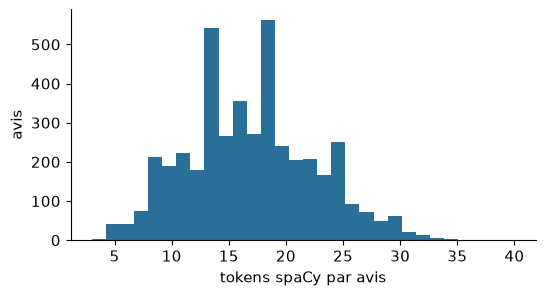

{'boutique': 17.7, 'livraison': 17.6, 'restaurant': 16.3, 'transport': 16.3}


In [6]:
# Longueur en tokens spaCy (tokenizer seul : rapide)
avis_brut["n_tokens"] = [len(d) for d in nlp.tokenizer.pipe(avis_brut["texte"], batch_size=256)]
print(avis_brut["n_tokens"].describe().round(1))
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(avis_brut["n_tokens"], bins=30, color="#2a6f97"); ax.set_xlabel("tokens spaCy par avis"); ax.set_ylabel("avis")
plt.show()
print(avis_brut.groupby("domaine")["n_tokens"].mean().round(1).to_dict())

In [7]:
# Mots de wolof : on cherche d'abord les mots inconnus du modèle français (sans vecteur), puis on fixe la liste
cand = Counter(t.lower_ for d in nlp.tokenizer.pipe(avis_brut["texte"]) for t in d
               if t.is_alpha and not nlp.vocab[t.lower_].has_vector)
print("Mots sans vecteur les plus fréquents :", cand.most_common(40))

Mots sans vecteur les plus fréquents : [('jërëjëf', 502), ('thiéboudienne', 282), ('rufisque', 167), ('metti', 162), ('pikine', 154), ('ngor', 138), ('thiès', 119), ('neexul', 50), ('neex', 44)]


In [8]:
# Liste de départ (à compléter si l'exploration ci-dessus en révèle d'autres)
WOLOF = ["jërëjëf", "dafa", "neex", "neexul", "metti"]
re_wolof = re.compile(r"\b(" + "|".join(WOLOF) + r")\b", re.I)
a_wolof = avis_brut["texte"].str.contains(re_wolof)
a_mais = avis_brut["texte"].str.contains(r"\bmais\b", case=False, regex=True)
print(f"Avis contenant au moins un mot de wolof : {a_wolof.mean():.1%} ({a_wolof.sum()})")
print(f"Avis contenant « mais »                  : {a_mais.mean():.1%} ({a_mais.sum()})")

Avis contenant au moins un mot de wolof : 16.8% (732)
Avis contenant « mais »                  : 18.0% (785)


In [9]:
# Doublons retirés AVANT tout découpage, puis découpage imposé 60/20/20
avis = avis_brut.drop(columns="n_tokens").drop_duplicates("texte").reset_index(drop=True)
avis["y"] = (avis["sentiment"] == "positif").astype(int)
print("Après dédoublonnage :", avis.shape)

train, reste = train_test_split(avis, test_size=0.4, random_state=0, stratify=avis["sentiment"])
val, test = train_test_split(reste, test_size=0.5, random_state=0, stratify=reste["sentiment"])
train, val, test = (d.reset_index(drop=True) for d in (train, val, test))
print("train / val / test :", len(train), len(val), len(test))
print("positifs :", [round(d["y"].mean(), 3) for d in (train, val, test)])
assert not (set(train["texte"]) & set(val["texte"])) and not (set(train["texte"]) & set(test["texte"]))

Après dédoublonnage : (4022, 5)
train / val / test : 2413 804 805
positifs : [np.float64(0.555), np.float64(0.555), np.float64(0.555)]


**Q1.1 [Interprétation]** *(5 à 10 lignes à rédiger : textes à deux étiquettes, fiabilité des étiquettes, plafond de performance.)*

**Conclusion de la partie 1.** *(à rédiger)*

## Partie 2 · Extraire et anonymiser avec spaCy
Aucun message brut ne doit apparaître dans les sorties, sauf les **5 exemples** demandés. Les 30 messages à vérifier à la main sont donc écrits dans un fichier local `verif_30.csv` (à ouvrir hors notebook, à ne pas rendre).

In [10]:
messages = pd.read_csv(MESSAGES_CSV)
print(messages.shape)

RE_CMD = re.compile(r"\bCMD-\d+\b")
RE_TEL = re.compile(r"(?<!\d)(?:\+?221[ .\-]?)?7[05678](?:[ .\-]?\d){7}(?!\d)")
RE_MONTANT = re.compile(
    r"(?<![\w+.])(?:\d{1,3}(?:[ .\u00a0\u202f]\d{3})+|\d+)\s?(?:FCFA|CFA|francs?|F)\b", re.I)

def reperer(texte):
    # Renvoie [(debut, fin, etiquette)] ; les regex passent avant spaCy, sans chevauchement
    spans = []
    libre = lambda a, b: not any(a < e and s < b for s, e, _ in spans)
    for etiquette, rx in [("COMMANDE", RE_CMD), ("TEL", RE_TEL), ("MONTANT", RE_MONTANT)]:
        for m in rx.finditer(texte):
            if libre(m.start(), m.end()):
                spans.append((m.start(), m.end(), etiquette))
    for ent in nlp(texte).ents:
        if ent.label_ == "PER" and libre(ent.start_char, ent.end_char):
            spans.append((ent.start_char, ent.end_char, "NOM"))
    return sorted(spans)

def anonymiser(texte):
    for debut, fin, etiquette in reversed(reperer(texte)):
        texte = texte[:debut] + f"[{etiquette}]" + texte[fin:]
    return texte

messages["anonymise"] = messages["texte"].map(anonymiser)
messages[["message_id", "anonymise"]].rename(columns={"anonymise": "texte"}).to_csv("messages_anonymises.csv", index=False)
comptes = Counter(e for t in messages["texte"] for _, _, e in reperer(t))
print("Éléments repérés sur les 320 messages :", dict(comptes))
print(messages["anonymise"].head(5).to_string())      # versions anonymisées uniquement

(320, 2)
Éléments repérés sur les 320 messages : {'MONTANT': 223, 'NOM': 261, 'COMMANDE': 122, 'TEL': 126}
0         J'ai payé [MONTANT] pour la livraison à Thiès mais le livreur a demandé [MONTANT] en plus. Merci de me rembourser. [NOM]
1                                    Vous m'avez facturé [MONTANT] au lieu de [MONTANT] pour la commande [COMMANDE]. [NOM], Thiès.
2                               Vous m'avez facturé [MONTANT] au lieu de [MONTANT] pour la commande [COMMANDE]. [NOM], Ziguinchor.
3          Bonjour, je suis [NOM]. Ma commande [COMMANDE] passée le 19 décembre n'est toujours pas arrivée. Rappelez-moi au [TEL].
4    J'ai payé [MONTANT] pour la livraison à Ziguinchor mais le livreur a demandé [MONTANT] en plus. Merci de me rembourser. [NOM]


In [11]:
# Fichier de travail pour la vérification manuelle (30 messages, random_state=0) : à ouvrir HORS notebook
echantillon = messages.sample(30, random_state=0).copy()
def detail(texte):
    d = {"NOM": [], "TEL": [], "MONTANT": [], "COMMANDE": []}
    for s, e, lab in reperer(texte):
        d[lab].append(texte[s:e])
    return d
det = echantillon["texte"].map(detail)
for lab in ["NOM", "TEL", "MONTANT", "COMMANDE"]:
    echantillon["trouves_" + lab] = det.map(lambda d: " | ".join(d[lab]))
echantillon[["message_id", "texte"] + [c for c in echantillon.columns if c.startswith("trouves_")]].to_csv("verif_30.csv", index=False)
print("verif_30.csv écrit : pour chaque type, comptez à la main les éléments trouvés à raison, oubliés, trouvés à tort.")

verif_30.csv écrit : pour chaque type, comptez à la main les éléments trouvés à raison, oubliés, trouvés à tort.


In [12]:
# À REMPLIR À LA MAIN après lecture de verif_30.csv : (trouvés à raison, oubliés, trouvés à tort)
verif = {
    "NOM":      (None, None, None),
    "TEL":      (None, None, None),
    "MONTANT":  (None, None, None),
    "COMMANDE": (None, None, None),
}
if all(v[0] is not None for v in verif.values()):
    lignes = []
    for lab, (tp, fn, fp) in verif.items():
        lignes.append({"type": lab, "à raison": tp, "oubliés": fn, "à tort": fp,
                       "précision": round(tp / (tp + fp), 3) if tp + fp else None,
                       "rappel": round(tp / (tp + fn), 3) if tp + fn else None})
    display(pd.DataFrame(lignes))
else:
    print("Remplir le dictionnaire verif ci-dessus.")

Remplir le dictionnaire verif ci-dessus.


In [13]:
# Aide pour trouver les erreurs : on n'affiche que des textes ANONYMISÉS
LIEUX = {"Dakar", "Thiès", "Saint-Louis", "Touba", "Ziguinchor", "Mbour", "Kaolack", "Rufisque", "Pikine", "Ngor"}
MARQUES = {"NOM", "TEL", "MONTANT", "COMMANDE"}
suspects = []
for _, r in messages.iterrows():
    doc = nlp(r["anonymise"])
    restes = [t.text for t in doc if t.text[:1].isupper() and not t.is_sent_start
              and t.text not in LIEUX and t.text not in MARQUES]
    mal = [e.text for e in nlp(r["texte"]).ents if e.label_ == "PER" and (e.text in LIEUX or any(c.isdigit() for c in e.text))]
    if restes or mal:
        suspects.append((r["message_id"], restes, mal, r["anonymise"]))
print(len(suspects), "messages suspects (mots capitalisés restants = noms peut-être oubliés ; mal = lieu ou nombre pris pour un nom)")
for s in suspects[:15]:
    print(s)

101 messages suspects (mots capitalisés restants = noms peut-être oubliés ; mal = lieu ou nombre pris pour un nom)
('M0002', [], ['CMD-13125'], "Vous m'avez facturé [MONTANT] au lieu de [MONTANT] pour la commande [COMMANDE]. [NOM], Thiès.")
('M0004', ['NOM].', 'TEL].'], [], "Bonjour, je suis [NOM]. Ma commande [COMMANDE] passée le 19 décembre n'est toujours pas arrivée. Rappelez-moi au [TEL].")
('M0014', ['Je'], [], 'Le chauffeur [NOM] a été très correct, trajet Rufisque – Dakar pour [MONTANT]. Je recommande.')
('M0015', ['NOM].', 'TEL].'], [], "Bonjour, je suis [NOM]. Ma commande [COMMANDE] passée le 12 octobre n'est toujours pas arrivée. Rappelez-moi au [TEL].")
('M0017', ['MONTANT].', 'Je'], [], 'Le chauffeur [NOM] a été très correct, trajet Dakar – Dakar pour [MONTANT]. Je recommande.')
('M0020', ['NOM].', 'TEL].'], [], "Bonjour, je suis [NOM]. Ma commande [COMMANDE] passée le 16/04/2025 n'est toujours pas arrivée. Rappelez-moi au [TEL].")
('M0026', ['Je'], [], 'Le chauffeur [NOM] 

In [14]:
# Les 5 exemples avant / après (seuls messages bruts autorisés dans les sorties) : choisissez-en au moins 2 où la fonction se trompe
IDS_EXEMPLES = None          # ex. ["M0007", "M0042", "M0100", "M0150", "M0203"]
if IDS_EXEMPLES is None:
    IDS_EXEMPLES = list(messages.sample(5, random_state=1)["message_id"])
for _, r in messages[messages["message_id"].isin(IDS_EXEMPLES)].iterrows():
    print(r["message_id"], "\n  avant :", r["texte"], "\n  après :", r["anonymise"], "\n")

M0081 
  avant : Mon frère Babacar Ndiaye a essayé de vous joindre le 13 décembre au 706348428, sans réponse. 
  après : Mon frère [NOM] a essayé de vous joindre le 13 décembre au [TEL], sans réponse. 

M0111 
  avant : Vous m'avez facturé 500 francs au lieu de 3500 F pour la commande CMD-30126. Aminata Ba, Rufisque. 
  après : Vous m'avez facturé [MONTANT] au lieu de [MONTANT] pour la commande [COMMANDE]. [NOM], Rufisque. 

M0124 
  avant : Bonsoir, le colis CMD-95086 est arrivé abîmé. Je veux un échange. Contact : +221769417206 (Aminata Kane). 
  après : Bonsoir, le colis [COMMANDE] est arrivé abîmé. Je veux un échange. Contact : [TEL] (Aminata Kane). 

M0132 
  avant : Remboursement de 2 500 CFA toujours en attente depuis ce matin. Mon numéro : +221760341806. 
  après : Remboursement de [MONTANT] toujours en attente depuis ce matin. Mon numéro : [TEL]. 

M0133 
  avant : J'ai payé 2500 francs pour la livraison à Touba mais le livreur a demandé 1.500 francs en plus. Merci de me rembo

**Q2.1 [Interprétation]** *(nom oublié ou mot masqué à tort, compromis précision/rappel, appuyé sur vos erreurs observées.)*

**Conclusion de la partie 2.** *(à rédiger)*

## Partie 3 · Lire les avis : analyse linguistique (ensemble d'entraînement uniquement)

In [15]:
docs_train = list(nlp.pipe(train["texte"], batch_size=128))
UPOS = {"NOUN", "ADJ", "VERB"}
train["lemmes"] = [[t.lemma_.lower() for t in d if t.pos_ in UPOS and t.is_alpha and not t.is_stop] for d in docs_train]
print(len(docs_train), "avis analysés ;", train["lemmes"].head(3).tolist())

2413 avis analysés ; [['habitude', 'livreur', 'aimable', 'livraison', 'arriver', 'heure', 'recommander'], ['jus', 'bissap', 'excellent', 'service', 'rapide', 'revenir'], ['fois', 'thiéboudienne', 'saler', 'service', 'lent', 'revenir']]


In [16]:
# Q3.1 : lemmes les plus caractéristiques = log du rapport des fréquences relatives (lissage +0,5)
def lexique(dom, k=10, min_total=5):
    sub = train[train["domaine"] == dom]
    cn = Counter(l for ls in sub[sub["sentiment"] == "négatif"]["lemmes"] for l in ls)
    cp = Counter(l for ls in sub[sub["sentiment"] == "positif"]["lemmes"] for l in ls)
    Nn, Np = sum(cn.values()), sum(cp.values())
    score = {l: np.log(((cn[l] + .5) / Nn) / ((cp[l] + .5) / Np)) for l in set(cn) | set(cp) if cn[l] + cp[l] >= min_total}
    tri = sorted(score, key=score.get)
    return [f"{l} ({cn[l]}/{cp[l]})" for l in tri[::-1][:k]], [f"{l} ({cn[l]}/{cp[l]})" for l in tri[:k]]

for dom in sorted(train["domaine"].unique()):
    neg, pos = lexique(dom)
    print(f"\n=== {dom} === (entre parenthèses : fréquence dans négatifs / positifs)")
    display(pd.DataFrame({"négatif": neg, "positif": pos}))


=== boutique === (entre parenthèses : fréquence dans négatifs / positifs)


,négatif,positif
0,éviter (23/1),reprocher (0/17)
1,dommage (36/2),correct (1/25)
2,terrible (19/1),raisonnable (2/25)
3,impoli (64/6),neuf (8/72)
4,lent (14/1),accueillant (8/69)
5,service (14/1),équipe (4/30)
6,hauteur (10/1),problème (3/20)
7,tomber (60/9),refaire (5/30)
8,panne (60/9),qualité (20/113)
9,semaine (60/9),conseil (10/55)



=== livraison === (entre parenthèses : fréquence dans négatifs / positifs)


,négatif,positif
0,éviter (30/3),venir (5/76)
1,incomplet (54/6),appeler (5/76)
2,adresse (60/8),raisonnable (2/25)
3,trouver (60/8),correct (2/24)
4,abîmer (35/5),aimable (9/70)
5,satisfait (9/1),emballer (10/68)
6,lent (14/2),intact (13/86)
7,service (14/2),problème (3/21)
8,dommage (31/5),équipe (8/45)
9,retard (67/12),refaire (9/48)



=== restaurant === (entre parenthèses : fréquence dans négatifs / positifs)


,négatif,positif
0,neexul (25/1),sourire (0/16)
1,dommage (34/2),grillé (1/48)
2,hauteur (15/1),équipe (2/39)
3,grer (14/1),mal (0/6)
4,désagréable (29/3),braiser (2/31)
5,fade (28/3),excellent (3/42)
6,éviter (35/5),jus (3/42)
7,saler (22/3),raisonnable (2/27)
8,satisfait (13/2),problème (1/12)
9,lent (39/7),mauvais (1/12)



=== transport === (entre parenthèses : fréquence dans négatifs / positifs)


,négatif,positif
0,satisfait (12/0),refaire (0/37)
1,dommage (25/1),équipe (0/36)
2,éviter (37/3),reprocher (0/15)
3,refuser (52/6),correct (1/28)
4,convenir (52/6),raisonnable (1/24)
5,terrible (16/2),problème (1/19)
6,sale (54/8),mauvais (2/25)
7,rouler (54/10),rapide (7/75)
8,pénible (47/11),rapport (3/32)
9,éternité (63/15),qualité (6/51)


In [17]:
# Q3.2 : sujets (nsubj) des phrases négatives. On retient les avis négatifs SANS « mais » pour ne pas mélanger des clauses positives.
masque_mais = train["texte"].str.contains(r"\bmais\b", case=False, regex=True)
neg_pur = train[(train["sentiment"] == "négatif") & ~masque_mais]
lignes = []
for i in neg_pur.index:
    d = docs_train[i]
    for t in d:
        if t.dep_ == "nsubj" and t.pos_ in {"NOUN", "PROPN"}:
            lignes.append((train.at[i, "domaine"], t.lemma_.lower(), t.head.lemma_.lower(), d.text))
suj = pd.DataFrame(lignes, columns=["domaine", "sujet", "verbe", "texte"])
print(len(neg_pur), "avis négatifs sans « mais » ;", len(suj), "sujets extraits")
for dom, g in suj.groupby("domaine"):
    print(dom, g["sujet"].value_counts().head(8).to_dict())

860 avis négatifs sans « mais » ; 1144 sujets extraits
boutique {'tissu': 104, 'vendeur': 102, 'téléphone': 48, 'prix': 22, 'dafa': 1}
livraison {'livraison': 103, 'livreur': 102, 'colis': 82, 'prix': 14, 'dafa': 5}
restaurant {'mafé': 53, 'bissap': 46, 'thiéboudienne': 44, 'service': 26, 'serveur': 24, 'poisson': 23, 'yassa': 23, 'prix': 14}
transport {'trajet': 94, 'chauffeur': 93, 'taxi': 92, 'prix': 14, 'dafa': 2, 'tout': 1}


In [18]:
# Complétez PERSONNES d'après la liste ci-dessus (lemmes qui désignent une personne)
PERSONNES = {"livreur", "chauffeur", "vendeuse", "serveur", "vendeur", "équipe", "personnel"}
suj["type"] = np.where(suj["sujet"].isin(PERSONNES), "personne", "chose")
print((pd.crosstab(suj["domaine"], suj["type"], normalize="index") * 100).round(1))
print(suj["type"].value_counts(normalize=True).round(3).to_dict())

# Erreurs de l'analyseur : sujets inattendus (non nominaux) et lecture de phrases
print("\nSujets de nature inattendue :")
bizarres = []
for i in neg_pur.index:
    for t in docs_train[i]:
        if t.dep_ == "nsubj" and t.pos_ not in {"NOUN", "PROPN", "PRON"}:
            bizarres.append((t.text, t.pos_, t.head.text, docs_train[i].text))
for b in bizarres[:10]:
    print(b)
print("\nAnalyse de 10 phrases tirées au hasard (relevez au moins 3 erreurs) :")
for i in neg_pur.sample(10, random_state=0).index:
    d = docs_train[i]
    print(d.text, "\n   ", [(t.text, t.dep_, t.head.text) for t in d if t.dep_ in ("nsubj", "obj", "ROOT")])

type        chose  personne
domaine                    
boutique     63.2      36.8
livraison    66.7      33.3
restaurant   90.9       9.1
transport    68.6      31.4
{'chose': 0.719, 'personne': 0.281}

Sujets de nature inattendue :
('yassa', 'VERB', 'fade', 'Jërëjëf ! Le thiéboudienne était trop salé. Le yassa était fade.')

Analyse de 10 phrases tirées au hasard (relevez au moins 3 erreurs) :
Hier soir à Thiès, ce n'était pas bon, le livreur a été impoli. Dommage. 
    [('ce', 'nsubj', 'bon'), ('livreur', 'nsubj', 'impoli'), ('impoli', 'ROOT', 'impoli'), ('Dommage', 'ROOT', 'Dommage')]
Bon, le chauffeur parlait au téléphone en conduisant. Le taxi était sale et dafa metti, trop cher pour ce que c'est. Dommage. 
    [('Bon', 'ROOT', 'Bon'), ('chauffeur', 'nsubj', 'parlait'), ('parlait', 'ROOT', 'parlait'), ('taxi', 'nsubj', 'sale'), ('sale', 'ROOT', 'sale'), ('que', 'obj', 'est'), ("c'", 'nsubj', 'est'), ('Dommage', 'ROOT', 'Dommage')]
Ce matin à Touba, je ne recommande pas. Le servi

In [19]:
# Q3.3 : « c'est la partie après "mais" qui donne le sentiment ». Juge de polarité d'une clause : TF-IDF entraîné
# sur les avis d'entraînement SANS « mais » (pas de fuite : ensemble d'entraînement uniquement).
juge = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2), LogisticRegression(max_iter=2000, C=10))
juge.fit(train.loc[~masque_mais, "texte"], train.loc[~masque_mais, "y"])

avec = train[masque_mais].copy()
parts = avec["texte"].str.split(r"\bmais\b", n=1, regex=True, expand=True)
ok = parts[1].fillna("").str.strip().str.len().gt(0) & parts[0].fillna("").str.strip().str.len().gt(0)
avec, parts = avec[ok], parts[ok]
avec["p_avant"] = juge.predict(parts[0].str.strip())
avec["p_apres"] = juge.predict(parts[1].str.strip())
n = len(avec)
print(f"Avis avec « mais » : {n}")
print(f"Partie APRÈS = étiquette : {(avec['p_apres'] == avec['y']).mean():.1%}")
print(f"Partie AVANT = étiquette : {(avec['p_avant'] == avec['y']).mean():.1%}")
print(f"Avant et après de polarités opposées : {(avec['p_avant'] != avec['p_apres']).mean():.1%}")
opp = avec[avec["p_avant"] != avec["p_apres"]]
print(f"Parmi les avis où avant ≠ après ({len(opp)}), la partie après donne l'étiquette dans {(opp['p_apres'] == opp['y']).mean():.1%} des cas")
print("\n15 avis nuancés à lire :")
for _, r in avec.sample(15, random_state=0).iterrows():
    print(f"[{r['sentiment']:<7}] {r['texte']}")

Avis avec « mais » : 476
Partie APRÈS = étiquette : 72.3%
Partie AVANT = étiquette : 36.1%
Avant et après de polarités opposées : 89.5%
Parmi les avis où avant ≠ après (426), la partie après donne l'étiquette dans 70.2% des cas

15 avis nuancés à lire :
[négatif] Le téléphone fonctionne parfaitement mais ce n'était pas bon. Je ne reviendrai pas.
[négatif] Bon rapport qualité-prix mais le téléphone est tombé en panne après une semaine, la vendeuse a été impolie.
[positif] Bon, le téléphone était bien neuf mais le tissu s'est déchiré au premier lavage mais pas mal du tout. Je recommande !
[positif] Le trajet a été pénible mais le taxi était propre. Le trajet a été agréable.
[positif] Jërëjëf ! Le trajet a été pénible mais les prix sont corrects. Je reviendrai.
[positif] Première fois à Ziguinchor : le taxi était sale mais le chauffeur était courtois. Merci à toute l'équipe.
[négatif] Bon, le yassa était bien relevé mais le bissap était trop sucré.
[positif] C'est beaucoup trop cher mais 

In [20]:
# Q3.4 : le wolof, mot par mot (ensemble d'entraînement)
base = train["y"].mean()
lignes = []
for mot in WOLOF:
    m = train["texte"].str.contains(rf"\b{mot}\b", case=False, regex=True)
    lignes.append({"mot": mot, "avis": int(m.sum()), "% positifs": round(100 * train.loc[m, "y"].mean(), 1) if m.any() else None,
                   "domaines": train.loc[m, "domaine"].value_counts().to_dict()})
print(f"Part de positifs dans le train : {100 * base:.1f} %")
display(pd.DataFrame(lignes))
w = train["texte"].str.contains(re_wolof)
print(f"Avis avec wolof : {w.sum()} ({w.mean():.1%}) ; part de positifs : {train.loc[w, 'y'].mean():.1%}")

Part de positifs dans le train : 55.5 %


,mot,avis,% positifs,domaines
0,jërëjëf,279,54.8,"{'restaurant': 86, 'transport': 69, 'livraison': 62, 'boutique': 62}"
1,dafa,113,25.7,"{'restaurant': 41, 'livraison': 25, 'boutique': 24, 'transport': 23}"
2,neex,24,83.3,{'restaurant': 24}
3,neexul,26,3.8,{'restaurant': 26}
4,metti,89,10.1,"{'livraison': 25, 'boutique': 24, 'transport': 23, 'restaurant': 17}"


Avis avec wolof : 405 (16.8%) ; part de positifs : 44.2%


**Q3.1 – Q3.4 [Interprétation]** *(une réponse de 5 à 10 lignes par question, avec chiffres et exemples des sorties ci-dessus.)*

**Conclusion de la partie 3.** *(à rédiger)*

## Partie 4 · Référence TF-IDF
Les variantes se comparent **sur la validation** ; le test n'est utilisé qu'**une seule fois**, pour la variante retenue.

In [21]:
NEG = {"ne", "pas", "jamais", "rien", "aucun", "plus", "sans"}
def lemmatiser(textes, garder_neg=False):
    sortie = []
    with nlp.select_pipes(disable=["parser", "ner"]):
        for doc in nlp.pipe(list(textes), batch_size=128):
            sortie.append(" ".join(t.lemma_.lower() for t in doc if not t.is_punct and not t.is_space
                                   and (not t.is_stop or (garder_neg and (t.lemma_.lower() in NEG or t.lower_ in NEG)))))
    return sortie

def preparer(textes, mode):
    if mode == "brut": return list(textes)
    if mode == "lem_sans_vides": return lemmatiser(textes, garder_neg=False)   # « ne » et « pas » disparaissent
    if mode == "lem_garde_neg": return lemmatiser(textes, garder_neg=True)
    raise ValueError(mode)

X = {mode: {nom: preparer(d["texte"], mode) for nom, d in [("train", train), ("val", val), ("test", test)]}
     for mode in ["brut", "lem_sans_vides", "lem_garde_neg"]}
print("Exemple lemmatisé sans mots vides :", X["lem_sans_vides"]["train"][0])
print("Exemple lemmatisé, négation gardée :", X["lem_garde_neg"]["train"][0])

Exemple lemmatisé sans mots vides : habitude livreur être aimable livraison arriver heure recommander
Exemple lemmatisé, négation gardée : habitude livreur être aimable livraison arriver heure recommander


In [22]:
STOP_SPACY = sorted(nlp.Defaults.stop_words)
print("« ne » et « pas » dans la liste de mots vides spaCy :", "ne" in STOP_SPACY, "pas" in STOP_SPACY)

VARIANTES = {
    "brut, (1,1), min_df=2":                dict(mode="brut", ngram_range=(1, 1), min_df=2),
    "brut, (1,2), min_df=2":                dict(mode="brut", ngram_range=(1, 2), min_df=2),
    "brut, (1,3), min_df=2":                dict(mode="brut", ngram_range=(1, 3), min_df=2),
    "brut, (1,2), min_df=5":                dict(mode="brut", ngram_range=(1, 2), min_df=5),
    "brut, (1,2), mots vides spaCy retirés": dict(mode="brut", ngram_range=(1, 2), min_df=2, stop_words=STOP_SPACY),
    "lemmes sans mots vides, (1,2)":        dict(mode="lem_sans_vides", ngram_range=(1, 2), min_df=2),
    "lemmes, négation conservée, (1,2)":    dict(mode="lem_garde_neg", ngram_range=(1, 2), min_df=2),
}
def construire(params):
    p = {k: v for k, v in params.items() if k != "mode"}
    return make_pipeline(TfidfVectorizer(**p), LogisticRegression(max_iter=2000, C=10))

resultats = []
for nom, params in VARIANTES.items():
    m = construire(params).fit(X[params["mode"]]["train"], train["y"])
    pv = m.predict(X[params["mode"]]["val"])
    resultats.append({"variante": nom, "F1 macro (validation)": round(f1_score(val["y"], pv, average="macro"), 4)})
tableau_val = pd.DataFrame(resultats).sort_values("F1 macro (validation)", ascending=False).reset_index(drop=True)
display(tableau_val)

« ne » et « pas » dans la liste de mots vides spaCy : True True


,variante,F1 macro (validation)
0,"brut, (1,3), min_df=2",0.9293
1,"brut, (1,2), min_df=5",0.9267
2,"brut, (1,1), min_df=2",0.9256
3,"brut, (1,2), min_df=2",0.9242
4,"brut, (1,2), mots vides spaCy retirés",0.9179
5,"lemmes sans mots vides, (1,2)",0.9166
6,"lemmes, négation conservée, (1,2)",0.9155


In [23]:
# Variante retenue = meilleure F1 sur la VALIDATION (modifiez le choix ici seulement d'après ce tableau)
nom_retenu = tableau_val.loc[0, "variante"]
params_retenus = VARIANTES[nom_retenu]
MODE = params_retenus["mode"]
tfidf = construire(params_retenus).fit(X[MODE]["train"], train["y"])
print("Variante retenue :", nom_retenu)

# ---- ÉVALUATION SUR LE TEST : une seule fois ----
p_tfidf_test = tfidf.predict_proba(X[MODE]["test"])[:, 1]
pred_tfidf_test = (p_tfidf_test > 0.5).astype(int)
f1_tfidf_test = f1_score(test["y"], pred_tfidf_test, average="macro")
print(f"F1 macro TEST : {f1_tfidf_test:.3f}")
print("Matrice de confusion (lignes = vrai [négatif, positif]) :\n", confusion_matrix(test["y"], pred_tfidf_test))
print("\nF1 macro par domaine :")
print({d: round(f1_score(test.loc[test["domaine"] == d, "y"], pred_tfidf_test[test["domaine"] == d], average="macro"), 3)
       for d in sorted(test["domaine"].unique())})

Variante retenue : brut, (1,3), min_df=2
F1 macro TEST : 0.927
Matrice de confusion (lignes = vrai [négatif, positif]) :
 [[326  32]
 [ 26 421]]

F1 macro par domaine :
{'boutique': 0.954, 'livraison': 0.921, 'restaurant': 0.888, 'transport': 0.946}


In [24]:
vec, clf = tfidf[0], tfidf[1]
noms = np.array(vec.get_feature_names_out()); ordre = clf.coef_[0].argsort()
print("15 n-grammes vers NÉGATIF :", ", ".join(noms[ordre[:15]]))
print("\n15 n-grammes vers POSITIF :", ", ".join(noms[ordre[::-1][:15]]))

15 n-grammes vers NÉGATIF : dommage, éviter, exagéré, est exagéré, prix est exagéré, ne, très déçu, trop, je ne, pas terrible, terrible, jërëjëf le livreur, habitude le téléphone, jërëjëf le chauffeur, sale

15 n-grammes vers POSITIF : était bien, bien, pas déçu, rapide, raisonnable, prix est raisonnable, est raisonnable, lent éviter, premier lavage mais, lavage mais, mais le chauffeur, trajet été rapide, impoli et le, jërëjëf le colis, était propre


**Q4.1 [Interprétation]** *(n-grammes porteurs de sens et artefacts de rédaction du corpus ; application à un autre style, par exemple un réseau social.)*

**Conclusion de la partie 4.** *(à rédiger : tableau des variantes, effet du retrait de « ne » et « pas », score test.)*

## Partie 5 · Un transformer avec Hugging Face

In [25]:
import torch
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, normalizers
from tokenizers.processors import TemplateProcessing
from transformers import (PreTrainedTokenizerFast, BertConfig, BertForSequenceClassification,
                          Trainer, TrainingArguments, DataCollatorWithPadding)

SPECIAUX = ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"]
tok = Tokenizer(models.WordPiece(unk_token="[UNK]"))
tok.normalizer = normalizers.Lowercase()
tok.pre_tokenizer = pre_tokenizers.BertPreTokenizer()
tok.train_from_iterator(train["texte"], trainers.WordPieceTrainer(vocab_size=1500, special_tokens=SPECIAUX))
tok.post_processor = TemplateProcessing(single="[CLS] $A [SEP]",
                                        special_tokens=[("[CLS]", tok.token_to_id("[CLS]")), ("[SEP]", tok.token_to_id("[SEP]"))])
tok.save("tokenizer_avis.json")
tok = Tokenizer.from_file("tokenizer_avis.json")          # on recharge le tokenizer sauvegardé
print("Vocabulaire :", tok.get_vocab_size())

mots = ["Ziguinchor", "Kédougou", "Tambacounda", "thiéboudienne", "jërëjëf", "neexul", "immangeable", "délicieuxxx", "livreurs", "Mbacké"]
for m in mots:
    print(f"{m:<15}", tok.encode(m).tokens)

Vocabulaire : 591
Ziguinchor      ['[CLS]', 'ziguinchor', '[SEP]']
Kédougou        ['[CLS]', 'k', '##é', '##d', '##ou', '##g', '##ou', '[SEP]']
Tambacounda     ['[CLS]', 'ta', '##m', '##ba', '##cou', '##n', '##d', '##a', '[SEP]']
thiéboudienne   ['[CLS]', 'thiéboudienne', '[SEP]']
jërëjëf         ['[CLS]', 'jërëjëf', '[SEP]']
neexul          ['[CLS]', 'neexul', '[SEP]']
immangeable     ['[CLS]', 'immangeable', '[SEP]']
délicieuxxx     ['[CLS]', 'délicieux', '##x', '##x', '[SEP]']
livreurs        ['[CLS]', 'livreur', '##s', '[SEP]']
Mbacké          ['[CLS]', 'mb', '##ac', '##k', '##é', '[SEP]']


In [26]:
tokenizer = PreTrainedTokenizerFast(tokenizer_object=tok, unk_token="[UNK]", pad_token="[PAD]",
                                    cls_token="[CLS]", sep_token="[SEP]", mask_token="[MASK]")
torch.manual_seed(SEED)
config = BertConfig(vocab_size=tokenizer.vocab_size, hidden_size=128, num_hidden_layers=2, num_attention_heads=4,
                    intermediate_size=256, max_position_embeddings=128, num_labels=2,
                    id2label={0: "négatif", 1: "positif"}, label2id={"négatif": 0, "positif": 1})
print(f"{sum(p.numel() for p in BertForSequenceClassification(config).parameters()):,} paramètres".replace(",", " "))

class Avis(torch.utils.data.Dataset):
    def __init__(self, df):
        self.enc = tokenizer(df["texte"].tolist(), truncation=True, max_length=64)
        self.y = df["y"].tolist()
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return {**{k: v[i] for k, v in self.enc.items()}, "labels": self.y[i]}

def metriques(pred):
    return {"f1": f1_score(pred.label_ids, pred.predictions.argmax(-1), average="macro")}

cle_eval = "eval_strategy" if "eval_strategy" in inspect.signature(TrainingArguments.__init__).parameters else "evaluation_strategy"
def arguments(epoques):
    return TrainingArguments(output_dir="mini_bert", num_train_epochs=epoques, learning_rate=1e-3,
                             per_device_train_batch_size=32, per_device_eval_batch_size=128, logging_strategy="epoch",
                             save_strategy="no", seed=SEED, report_to="none", disable_tqdm=True, **{cle_eval: "epoch"})
def entrainer(epoques):
    torch.manual_seed(SEED)
    return Trainer(model=BertForSequenceClassification(config), args=arguments(epoques), train_dataset=Avis(train),
                   eval_dataset=Avis(val), data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=metriques)

essai = entrainer(12); essai.train()
hist = essai.state.log_history
f1_val = {int(h["epoch"]): h["eval_f1"] for h in hist if "eval_f1" in h}
print("F1 validation par époque :", {e: round(f, 3) for e, f in f1_val.items()})
meilleure_epoque = max(f1_val, key=f1_val.get)
print("Meilleure époque sur la validation :", meilleure_epoque)

374 274 paramètres
{'loss': '0.44', 'grad_norm': '28.18', 'learning_rate': '0.0009178', 'epoch': '1'}
{'eval_loss': '0.2808', 'eval_f1': '0.9152', 'eval_runtime': '0.38', 'eval_samples_per_second': '2116', 'eval_steps_per_second': '18.42', 'epoch': '1'}
{'loss': '0.283', 'grad_norm': '9.706', 'learning_rate': '0.0008344', 'epoch': '2'}
{'eval_loss': '0.3037', 'eval_f1': '0.9056', 'eval_runtime': '0.3539', 'eval_samples_per_second': '2272', 'eval_steps_per_second': '19.78', 'epoch': '2'}
{'loss': '0.2489', 'grad_norm': '0.5457', 'learning_rate': '0.0007511', 'epoch': '3'}
{'eval_loss': '0.2372', 'eval_f1': '0.923', 'eval_runtime': '0.3982', 'eval_samples_per_second': '2019', 'eval_steps_per_second': '17.58', 'epoch': '3'}
{'loss': '0.2268', 'grad_norm': '1.253', 'learning_rate': '0.0006678', 'epoch': '4'}
{'eval_loss': '0.2563', 'eval_f1': '0.9083', 'eval_runtime': '0.3268', 'eval_samples_per_second': '2460', 'eval_steps_per_second': '21.42', 'epoch': '4'}
{'loss': '0.2182', 'grad_norm'

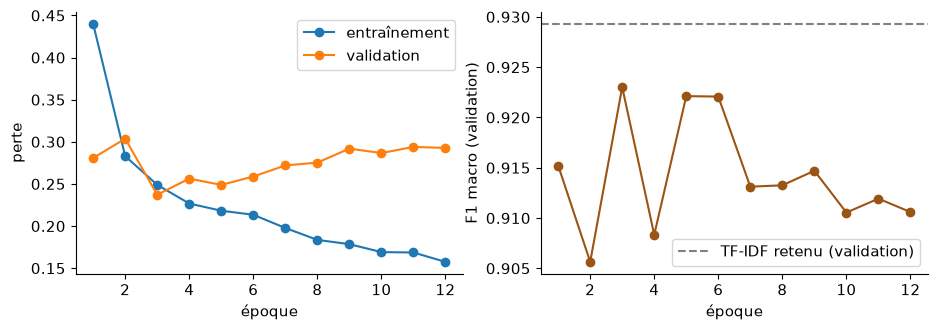

In [27]:
tl = [(h["epoch"], h["loss"]) for h in hist if "loss" in h and "eval_loss" not in h]
vl = [(h["epoch"], h["eval_loss"], h["eval_f1"]) for h in hist if "eval_loss" in h]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(*zip(*tl), marker="o", label="entraînement"); ax[0].plot([e for e, _, _ in vl], [l for _, l, _ in vl], marker="o", label="validation")
ax[0].set_xlabel("époque"); ax[0].set_ylabel("perte"); ax[0].legend()
ax[1].plot([e for e, _, _ in vl], [f for _, _, f in vl], marker="o", color="#9a5414"); ax[1].set_xlabel("époque"); ax[1].set_ylabel("F1 macro (validation)")
ax[1].axhline(tableau_val.loc[0, "F1 macro (validation)"], ls="--", color="grey", label="TF-IDF retenu (validation)"); ax[1].legend()
plt.show()

In [28]:
# Réentraînement avec le nombre d'époques choisi sur la validation (la décroissance du taux d'apprentissage dépend du total)
final = entrainer(meilleure_epoque); final.train()
modele_bert = final.model.eval()

def proba_bert(textes, bs=128):
    sortie = []
    with torch.no_grad():
        for i in range(0, len(textes), bs):
            enc = tokenizer(list(textes[i:i + bs]), padding=True, truncation=True, max_length=64, return_tensors="pt")
            enc = {k: v.to(modele_bert.device) for k, v in enc.items()}
            sortie.append(torch.softmax(modele_bert(**enc).logits, -1)[:, 1].cpu().numpy())
    return np.concatenate(sortie)

# ---- ÉVALUATION SUR LE TEST : une seule fois ----
p_bert_test = proba_bert(test["texte"].tolist())
pred_bert_test = (p_bert_test > 0.5).astype(int)
f1_bert_test = f1_score(test["y"], pred_bert_test, average="macro")
tableau = pd.DataFrame({"modèle": ["TF-IDF + régression logistique (" + nom_retenu + ")", f"Mini-BERT {config.num_hidden_layers} couches, {meilleure_epoque} époques"],
                        "F1 macro test": [round(f1_tfidf_test, 3), round(f1_bert_test, 3)]})
display(tableau)
final.save_model("mini_bert_avis"); tokenizer.save_pretrained("mini_bert_avis")

{'loss': '0.4533', 'grad_norm': '3.513', 'learning_rate': '0.0006711', 'epoch': '1'}
{'eval_loss': '0.2876', 'eval_f1': '0.9082', 'eval_runtime': '0.3049', 'eval_samples_per_second': '2637', 'eval_steps_per_second': '22.96', 'epoch': '1'}
{'loss': '0.2573', 'grad_norm': '4.243', 'learning_rate': '0.0003377', 'epoch': '2'}
{'eval_loss': '0.2612', 'eval_f1': '0.9175', 'eval_runtime': '0.3311', 'eval_samples_per_second': '2428', 'eval_steps_per_second': '21.14', 'epoch': '2'}
{'loss': '0.2194', 'grad_norm': '1.937', 'learning_rate': '4.386e-06', 'epoch': '3'}
{'eval_loss': '0.2427', 'eval_f1': '0.9194', 'eval_runtime': '0.3651', 'eval_samples_per_second': '2202', 'eval_steps_per_second': '19.17', 'epoch': '3'}
{'train_runtime': '14.07', 'train_samples_per_second': '514.3', 'train_steps_per_second': '16.2', 'train_loss': '0.31', 'epoch': '3'}


,modèle,F1 macro test
0,"TF-IDF + régression logistique (brut, (1,3), min_df=2)",0.927
1,"Mini-BERT 2 couches, 3 époques",0.916


Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 164.89it/s]


('mini_bert_avis\\tokenizer_config.json', 'mini_bert_avis\\tokenizer.json')

**Q5.1 [Interprétation]** *(le transformer bat-il TF-IDF ? explication : taille du corpus, absence de pré-entraînement, nature des avis ; conditions où vous le recommanderiez.)*

**Conclusion de la partie 5.** *(à rédiger)*

## Partie 6 · Ce que comprennent les modèles

In [29]:
# Q6.1 : erreurs des deux modèles sur le test (analyse a posteriori ; AUCUN réglage après ce point)
test["p_tfidf"], test["p_bert"] = p_tfidf_test, p_bert_test
test["err_tfidf"] = pred_tfidf_test != test["y"]
test["err_bert"] = pred_bert_test != test["y"]
err = test[test["err_tfidf"] | test["err_bert"]].copy()
err["qui"] = np.select([err["err_tfidf"] & err["err_bert"], err["err_tfidf"]], ["les deux", "TF-IDF seul"], "BERT seul")
print(f"Erreurs TF-IDF : {test['err_tfidf'].sum()} | BERT : {test['err_bert'].sum()} | communes : {(test['err_tfidf'] & test['err_bert']).sum()}")

re_neg = re.compile(r"\b(pas|jamais|aucun|rien)\b|\bn'|\bne\b", re.I)
def categorie(t):
    if re.search(r"\bmais\b", t, re.I): return "avis nuancé"
    if re_neg.search(t): return "négation"
    if re_wolof.search(t): return "wolof"
    return "autre"
err["categorie"] = err["texte"].map(categorie)
MANUEL = {}     # ex. {12: "étiquette douteuse"} : indices de err à reclasser après lecture
for i, c in MANUEL.items(): err.loc[i, "categorie"] = c
display(pd.crosstab(err["categorie"], err["qui"], margins=True))
print("\nErreurs à lire et à classer (au moins 20) :")
for i, r in err.sort_values("qui").head(30).iterrows():
    print(f"{i:>4} | vrai={r['sentiment']:<7} | TF-IDF={r['p_tfidf']:.2f} BERT={r['p_bert']:.2f} | {r['categorie']:<11} | {r['texte']}")

Erreurs TF-IDF : 58 | BERT : 67 | communes : 39


qui,BERT seul,TF-IDF seul,les deux,All
categorie,,,,
autre,0,1,10,11
avis nuancé,25,16,16,57
négation,3,2,11,16
wolof,0,0,2,2
All,28,19,39,86



Erreurs à lire et à classer (au moins 20) :
 385 | vrai=négatif | TF-IDF=0.23 BERT=0.60 | avis nuancé | Hier soir à Dakar, la livraison est arrivée avec deux heures de retard mais le prix est raisonnable mais pas du tout satisfait.
 391 | vrai=négatif | TF-IDF=0.44 BERT=0.96 | avis nuancé | Pas à la hauteur et pas terrible mais les prix sont corrects.
 403 | vrai=négatif | TF-IDF=0.32 BERT=0.73 | avis nuancé | Première fois à Ngor : le téléphone fonctionne parfaitement mais ce n'était pas bon. Très déçu.
 313 | vrai=positif | TF-IDF=0.93 BERT=0.29 | avis nuancé | Ce matin à Mbour, le poisson braisé était frais mais le bissap était trop sucré mais je n'ai rien à reprocher. Je reviendrai.
 416 | vrai=positif | TF-IDF=0.63 BERT=0.36 | avis nuancé | Jërëjëf ! Le colis était bien emballé. Pas mal du tout mais pas à la hauteur. Je ne reviendrai pas.
 459 | vrai=positif | TF-IDF=0.52 BERT=0.39 | avis nuancé | Jërëjëf ! Pas cher pour la qualité. Le colis était bien emballé mais le prix est ex

In [30]:
# Q6.2 : étiquettes douteuses sur la VALIDATION (les deux modèles très confiants contre l'étiquette)
p_tfidf_val = tfidf.predict_proba(X[MODE]["val"])[:, 1]
p_bert_val = proba_bert(val["texte"].tolist())
contre = np.where(val["y"] == 1, (p_tfidf_val < .1) & (p_bert_val < .1), (p_tfidf_val > .9) & (p_bert_val > .9))
dout = val[contre].copy(); dout["p_tfidf"], dout["p_bert"] = p_tfidf_val[contre], p_bert_val[contre]
print(f"{len(dout)} avis de validation sur {len(val)} où les deux modèles sont à plus de 0,9 contre l'étiquette")
display(dout[["texte", "sentiment", "p_tfidf", "p_bert"]].round(2))
N_ERRONEES = None     # nombre d'étiquettes qui vous paraissent fausses après lecture

30 avis de validation sur 804 où les deux modèles sont à plus de 0,9 contre l'étiquette


,texte,sentiment,p_tfidf,p_bert
2,"Hier soir à Saint-Louis, le serveur a été désagréable et le yassa était fade. À éviter.",positif,0.08,0.05
62,"Franchement, la vendeuse a été très accueillante, le tissu a gardé ses couleurs, pas mal du tout.",négatif,0.99,0.95
69,Bon rapport qualité-prix. Le chauffeur conduisait prudemment. Le taxi est arrivé vite. Je recommande !,négatif,0.98,0.96
73,Première fois à Pikine : pas terrible. Le poisson était brûlé. Dommage.,positif,0.10,0.04
109,"Hier soir à Rufisque, le livreur ne trouvait pas l'adresse, pas à la hauteur et le colis est arrivé abîmé.",positif,0.03,0.04
117,"Bon, le chauffeur était courtois et le chauffeur conduisait prudemment, pas cher pour la qualité.",négatif,0.97,0.96
136,"Le tissu est de très bonne qualité, le téléphone était bien neuf et le tissu a gardé ses couleurs. Je recommande !",négatif,0.98,0.96
154,"Bon, le prix est raisonnable. Aucun problème. Merci à toute l'équipe.",négatif,0.99,0.96
168,Jërëjëf ! Bon rapport qualité-prix.,négatif,0.94,0.96
206,"Ce matin à Touba, le livreur ne trouvait pas l'adresse, je ne recommande pas, c'est beaucoup trop cher. Très déçu.",positif,0.01,0.04


In [31]:
# Q6.3 : 10 phrases de test écrites par vous (ces phrases sont des BROUILLONS : remplacez-les par les vôtres)
PHRASES = [
    ("Le livreur n'a pas été désagréable.",                  1, "négation inédite"),
    ("Je ne dirais pas que le service était mauvais.",       1, "négation inédite"),
    ("Ce n'est pas faux de dire que le prix est exagéré.",   0, "double négation"),
    ("Bravo pour les deux heures de retard.",                0, "ironie"),
    ("Franchement, un vrai bonheur, ce retard de deux heures.", 0, "ironie"),
    ("Le yassa était meilleur que celui de la concurrence.", 1, "comparaison"),
    ("Moins cher qu'ailleurs, mais pas meilleur.",           0, "comparaison"),
    ("Dafa neex torop, jërëjëf.",                            1, "wolof seul"),
    ("Dafa metti, neexul.",                                  0, "wolof seul"),
    ("Rien à reprocher, vraiment rien.",                     1, "négation inédite"),
]
phr = pd.DataFrame(PHRASES, columns=["phrase", "attendu", "type"])
phr["p_tfidf"] = tfidf.predict_proba(preparer(phr["phrase"], MODE))[:, 1].round(2)
phr["p_bert"] = proba_bert(phr["phrase"].tolist()).round(2)
phr["TF-IDF ok"] = (phr["p_tfidf"] > .5).astype(int) == phr["attendu"]
phr["BERT ok"] = (phr["p_bert"] > .5).astype(int) == phr["attendu"]
display(phr)
print("Bonnes réponses : TF-IDF", int(phr["TF-IDF ok"].sum()), "/ 10 | BERT", int(phr["BERT ok"].sum()), "/ 10")

,phrase,attendu,type,p_tfidf,p_bert,TF-IDF ok,BERT ok
0,Le livreur n'a pas été désagréable.,1,négation inédite,0.05,0.07,False,False
1,Je ne dirais pas que le service était mauvais.,1,négation inédite,0.21,0.94,False,True
2,Ce n'est pas faux de dire que le prix est exagéré.,0,double négation,0.02,0.04,True,True
3,Bravo pour les deux heures de retard.,0,ironie,0.23,0.12,True,True
4,"Franchement, un vrai bonheur, ce retard de deux heures.",0,ironie,0.29,0.05,True,True
5,Le yassa était meilleur que celui de la concurrence.,1,comparaison,0.41,0.44,False,False
6,"Moins cher qu'ailleurs, mais pas meilleur.",0,comparaison,0.35,0.27,True,True
7,"Dafa neex torop, jërëjëf.",1,wolof seul,0.85,0.95,True,True
8,"Dafa metti, neexul.",0,wolof seul,0.16,0.04,True,True
9,"Rien à reprocher, vraiment rien.",1,négation inédite,0.84,0.96,True,True


Bonnes réponses : TF-IDF 7 / 10 | BERT 8 / 10


In [32]:
# Q6.4 : équité entre domaines (test)
lignes = []
for d in sorted(test["domaine"].unique()):
    s = test[test["domaine"] == d]
    ligne = {"domaine": d, "n": len(s)}
    for nom, col in [("TF-IDF", "p_tfidf"), ("BERT", "p_bert")]:
        pr = (s[col] > .5).astype(int)
        ligne[f"F1 {nom}"] = round(f1_score(s["y"], pr, average="macro"), 3)
        ligne[f"positifs jugés négatifs {nom} (%)"] = round(100 * ((pr == 0) & (s["y"] == 1)).sum() / max((s["y"] == 1).sum(), 1), 1)
        ligne[f"négatifs jugés positifs {nom} (%)"] = round(100 * ((pr == 1) & (s["y"] == 0)).sum() / max((s["y"] == 0).sum(), 1), 1)
    lignes.append(ligne)
display(pd.DataFrame(lignes))

,domaine,n,F1 TF-IDF,positifs jugés négatifs TF-IDF (%),négatifs jugés positifs TF-IDF (%),F1 BERT,positifs jugés négatifs BERT (%),négatifs jugés positifs BERT (%)
0,boutique,221,0.954,3.4,5.9,0.904,7.6,11.8
1,livraison,204,0.921,8.8,6.6,0.916,8.8,7.7
2,restaurant,207,0.888,8.0,14.7,0.922,7.1,8.4
3,transport,173,0.946,2.9,8.6,0.921,3.9,12.9


**Q6.1 – Q6.4 [Interprétation]** *(une réponse de 5 à 10 lignes par question, avec chiffres et exemples cités.)*

**Conclusion de la partie 6.** *(à rédiger)*

---
*Livrables : `TP6_Spacy_et_Hugging_Face.ipynb`, `messages_anonymises.csv`, `tokenizer_avis.json`, note PDF d'une page (partie 7).*

## Export pour l'application Streamlit
Sauvegarde le modèle TF-IDF retenu et sa configuration, pour `app.py` (le mini-BERT et le tokenizer sont déjà sauvegardés dans `mini_bert_avis/`).

In [33]:
import joblib
joblib.dump(tfidf, "tfidf_avis.joblib")
json.dump({"mode_tfidf": MODE, "variante": nom_retenu,
           "f1_test_tfidf": round(float(f1_tfidf_test), 4), "f1_test_bert": round(float(f1_bert_test), 4),
           "epoques_bert": int(meilleure_epoque)},
          open("config_app.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print("Fichiers pour l'application :", [p for p in ["tfidf_avis.joblib", "config_app.json", "mini_bert_avis", "tokenizer_avis.json"] if os.path.exists(p)])

Fichiers pour l'application : ['tfidf_avis.joblib', 'config_app.json', 'mini_bert_avis', 'tokenizer_avis.json']
